Import relevant libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style(style="whitegrid")



Import data and assign to respective dataframes

In [2]:
edgap = pd.read_excel('/Users/michael/Documents/SeattleU/5100/Education/data/EdGap_data.xlsx')

/opt/anaconda3/lib/python3.13/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Unknown extension is not supported and will be removed
  for idx, row in parser.parse():


In [3]:
edgap["NCESSCH School ID"] = edgap["NCESSCH School ID"].astype(object)
edgap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


Import school data

In [4]:
school_information = pd.read_csv(
    '/Users/michael/Documents/SeattleU/5100/Education/data/ccd_sch_029_1617_w_1a_11212017.csv', encoding = 'unicode_escape'
)


In [5]:
school_information.head()

,SCHOOL_YEAR,STATENAME,ST,SCH_NAME,LEA_NAME,ST_LEAID,LEAID,ST_SCHID,NCESSCH,SCHID,...,MZIP,LSTREET1,LCITY,LSTATE,LZIP,UPDATED_STATUS_TEXT,EFFECTIVE_DATE,SCH_TYPE_TEXT,SCH_TYPE,LEVEL
0,2016-2017,ALABAMA,AL,Sequoyah Sch - Chalkville Campus,Alabama Youth Services,AL-210,100002,AL-210-0020,1.000020e+10,100277,...,35220,1000 Industrial School Road,Birmingham,AL,35220,Open,3/3/10,Alternative School,4,High
1,2016-2017,ALABAMA,AL,Camps,Alabama Youth Services,AL-210,100002,AL-210-0050,1.000020e+10,101667,...,36057,1601 County Rd. 57,Prattville,AL,36067,Open,3/3/10,Alternative School,4,High
2,2016-2017,ALABAMA,AL,Det Ctr,Alabama Youth Services,AL-210,100002,AL-210-0060,1.000020e+10,101670,...,36057,2109 Bashi Rd Bldg 509,Thomasville,AL,36784,Open,3/3/10,Alternative School,4,High
3,2016-2017,ALABAMA,AL,Wallace Sch - Mt Meigs Campus,Alabama Youth Services,AL-210,100002,AL-210-0030,1.000020e+10,101705,...,36057,1000 Industrial School Road,Mount Meigs,AL,36057,Open,3/3/10,Alternative School,4,High
4,2016-2017,ALABAMA,AL,McNeel Sch - Vacca Campus,Alabama Youth Services,AL-210,100002,AL-210-0040,1.000020e+10,101706,...,35206,8950 Roebuck Blvd,Birmingham,AL,35206,Open,3/3/10,Alternative School,4,High


Use the info method to learn more about the dataframes

In [6]:
edgap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column                                           Non-Null Count  Dtype  
---  ------                                           --------------  -----  
 0   NCESSCH School ID                                7986 non-null   object 
 1   CT Unemployment Rate                             7972 non-null   float64
 2   CT Pct Adults with College Degree                7973 non-null   float64
 3   CT Pct Childre In Married Couple Family          7961 non-null   float64
 4   CT Median Household Income                       7966 non-null   float64
 5   School ACT average (or equivalent if SAT score)  7986 non-null   float64
 6   School Pct Free and Reduced Lunch                7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


In [7]:
school_information.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102181 entries, 0 to 102180
Data columns (total 23 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   SCHOOL_YEAR          102181 non-null  object 
 1   STATENAME            102181 non-null  object 
 2   ST                   102181 non-null  object 
 3   SCH_NAME             102181 non-null  object 
 4   LEA_NAME             102181 non-null  object 
 5   ST_LEAID             102181 non-null  object 
 6   LEAID                102181 non-null  int64  
 7   ST_SCHID             102181 non-null  object 
 8   NCESSCH              102181 non-null  float64
 9   SCHID                102181 non-null  int64  
 10  MSTREET1             102181 non-null  object 
 11  MCITY                102181 non-null  object 
 12  MSTATE               102181 non-null  object 
 13  MZIP                 102181 non-null  int64  
 14  LSTREET1             102181 non-null  object 
 15  LCITY            

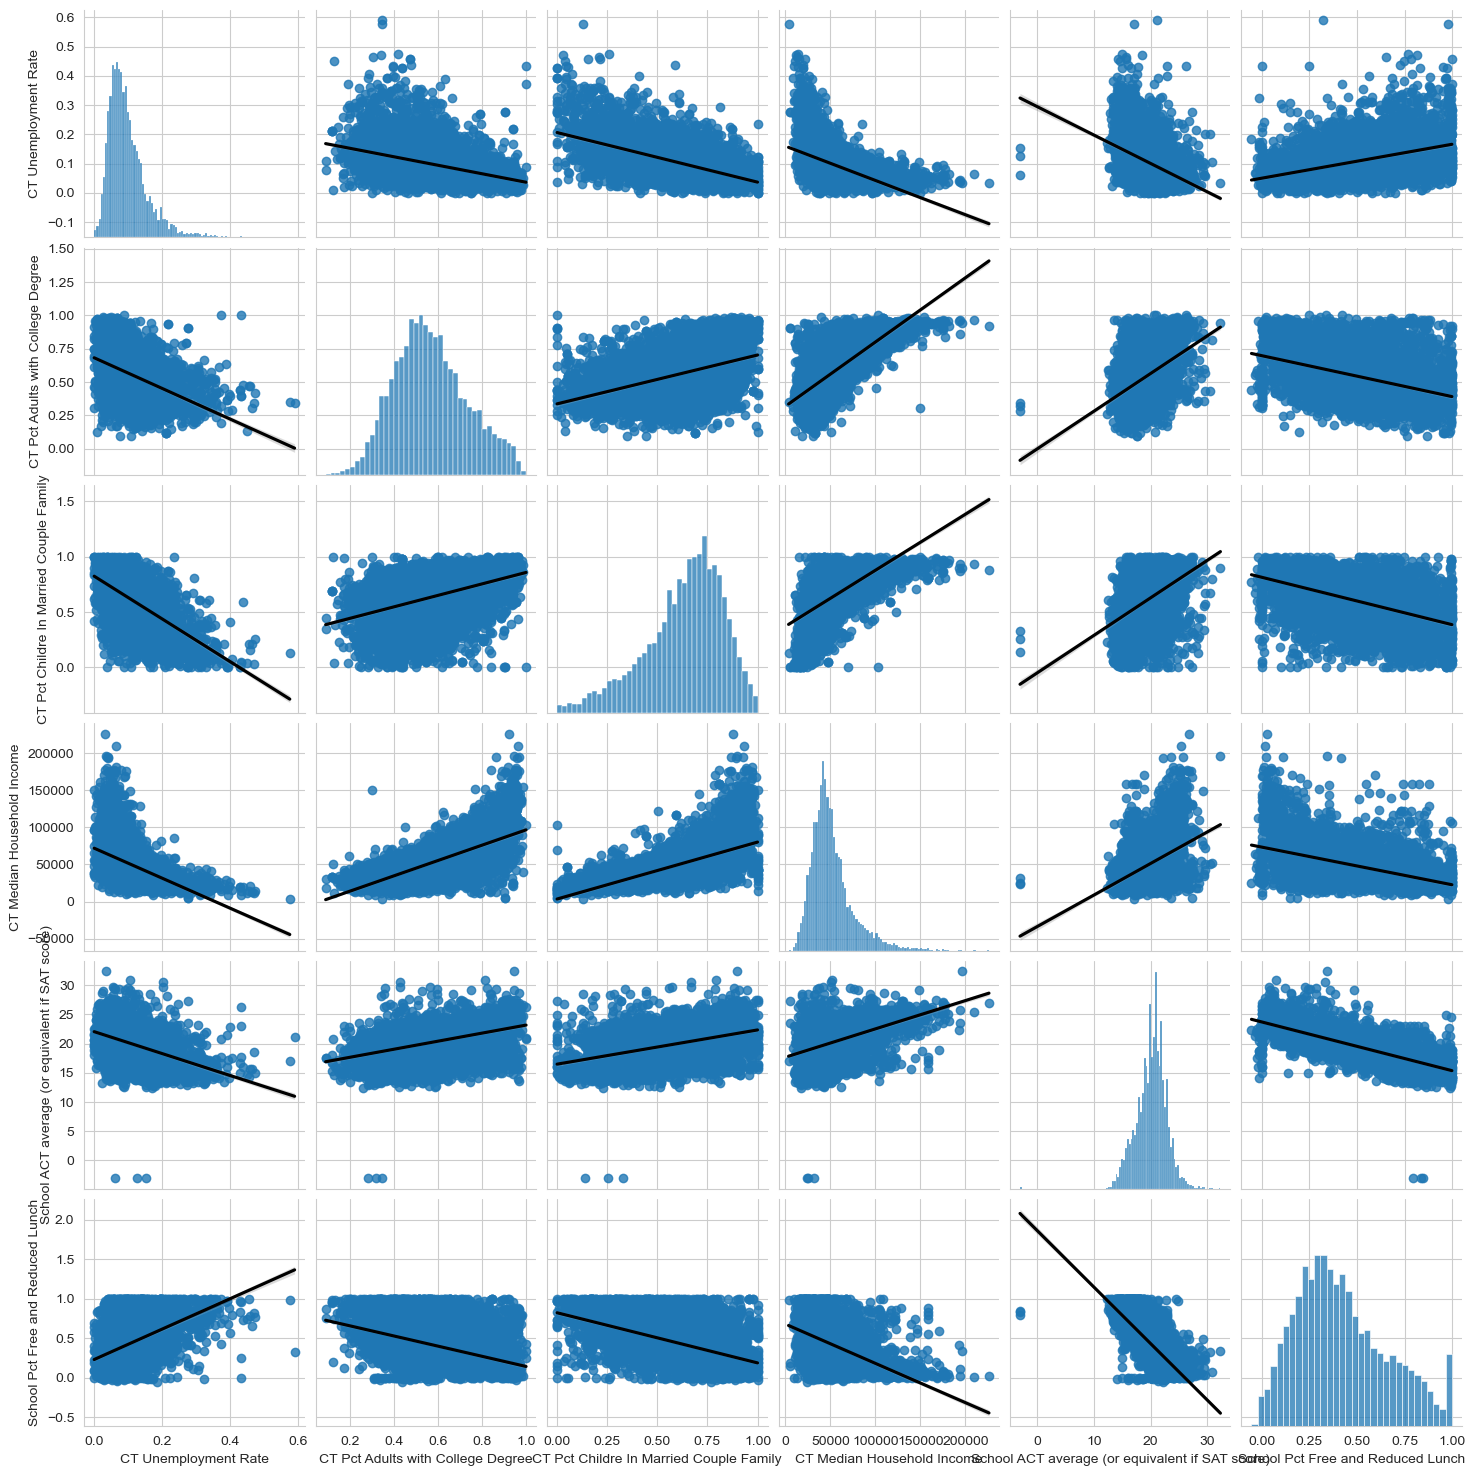

In [8]:
sns.pairplot(
    edgap.drop(columns="NCESSCH School ID"),
    kind="reg",
    plot_kws={
        "line_kws": {"color" : "black"}
    }
);


plt.show()

Select relevant subsets of the data

In [9]:
school_information = school_information[ 
    ['SCHOOL_YEAR', 'NCESSCH', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL']
]

#CHARTER TEXT not in this file, does that become important in future

In [10]:
school_information.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High


In [11]:
edgap = edgap.rename(
    columns={
        "NCESSCH School ID": "id",
        "CT Pct Adults with College Degree": "percent_college",
        "CT Unemployment Rate": "rate_unemployement",
        "CT Pct Childre In Married Couple Family": "percent_married",
        "CT Median Household Income": "median_income",
        "School ACT average (or equivalent if SAT score)": "average_act",
        "School Pct Free and Reduced Lunch" : "percent_lunch"
    }
        
)

In [12]:
edgap.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  7986 non-null   object 
 1   rate_unemployement  7972 non-null   float64
 2   percent_college     7973 non-null   float64
 3   percent_married     7961 non-null   float64
 4   median_income       7966 non-null   float64
 5   average_act         7986 non-null   float64
 6   percent_lunch       7986 non-null   float64
dtypes: float64(6), object(1)
memory usage: 436.9+ KB


In [13]:
edgap.head()

,id,rate_unemployement,percent_college,percent_married,median_income,average_act,percent_lunch
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641


In [14]:
school_information['id']= school_information['NCESSCH'].astype('Int64').astype('object')

In [15]:
school_information.head()

,SCHOOL_YEAR,NCESSCH,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL,id
0,2016-2017,1.000020e+10,AL,35220,Alternative School,High,10000200277
1,2016-2017,1.000020e+10,AL,36067,Alternative School,High,10000201667
2,2016-2017,1.000020e+10,AL,36784,Alternative School,High,10000201670
3,2016-2017,1.000020e+10,AL,36057,Alternative School,High,10000201705
4,2016-2017,1.000020e+10,AL,35206,Alternative School,High,10000201706


In [16]:
school_information = school_information[ 
    ['SCHOOL_YEAR', 'id', 'LSTATE', 'LZIP', 'SCH_TYPE_TEXT', 'LEVEL']
]


In [17]:
school_information.head()

,SCHOOL_YEAR,id,LSTATE,LZIP,SCH_TYPE_TEXT,LEVEL
0,2016-2017,10000200277,AL,35220,Alternative School,High
1,2016-2017,10000201667,AL,36067,Alternative School,High
2,2016-2017,10000201670,AL,36784,Alternative School,High
3,2016-2017,10000201705,AL,36057,Alternative School,High
4,2016-2017,10000201706,AL,35206,Alternative School,High


In [18]:
df = edgap.merge(
    school_information, 
    how='left',
    on='id', 
)

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  7986 non-null   object 
 1   rate_unemployement  7972 non-null   float64
 2   percent_college     7973 non-null   float64
 3   percent_married     7961 non-null   float64
 4   median_income       7966 non-null   float64
 5   average_act         7986 non-null   float64
 6   percent_lunch       7986 non-null   float64
 7   SCHOOL_YEAR         0 non-null      object 
 8   LSTATE              0 non-null      object 
 9   LZIP                0 non-null      float64
 10  SCH_TYPE_TEXT       0 non-null      object 
 11  LEVEL               0 non-null      object 
dtypes: float64(7), object(5)
memory usage: 748.8+ KB


In [22]:
df['LEVEL']

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
       ... 
7981    NaN
7982    NaN
7983    NaN
7984    NaN
7985    NaN
Name: LEVEL, Length: 7986, dtype: object

## Quality Control

In [23]:
df.describe()

,rate_unemployement,percent_college,percent_married,median_income,average_act,percent_lunch,LZIP
count,7972.000000,7973.000000,7961.000000,7966.000000,7986.000000,7986.000000,0.0
mean,0.098730,0.568930,0.633440,52026.905222,20.181532,0.420651,NaN
std,0.058959,0.165704,0.196764,24228.057079,2.595201,0.239754,NaN
min,0.000000,0.091493,0.000000,3589.000000,-3.070818,-0.054545,NaN
25%,0.058655,0.450828,0.523810,36597.250000,18.600000,0.238501,NaN
50%,0.085649,0.554979,0.667594,46833.500000,20.400000,0.381570,NaN
75%,0.123376,0.676571,0.777135,61369.250000,21.910867,0.575447,NaN
max,0.590278,1.000000,1.000000,226181.000000,32.362637,0.998729,NaN


In [24]:
df.select_dtypes(include=['number']).agg(['min', 'max']).round(2)

,rate_unemployement,percent_college,percent_married,median_income,average_act,percent_lunch,LZIP
min,0.00,0.09,0.0,3589.0,-3.07,-0.05,NaN
max,0.59,1.00,1.0,226181.0,32.36,1.00,NaN


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7986 entries, 0 to 7985
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  7986 non-null   object 
 1   rate_unemployement  7972 non-null   float64
 2   percent_college     7973 non-null   float64
 3   percent_married     7961 non-null   float64
 4   median_income       7966 non-null   float64
 5   average_act         7986 non-null   float64
 6   percent_lunch       7986 non-null   float64
 7   SCHOOL_YEAR         0 non-null      object 
 8   LSTATE              0 non-null      object 
 9   LZIP                0 non-null      float64
 10  SCH_TYPE_TEXT       0 non-null      object 
 11  LEVEL               0 non-null      object 
dtypes: float64(7), object(5)
memory usage: 748.8+ KB


Only keep data from the High School level

In [29]:
df = df.loc[df['SCHOOL_YEAR'] == 'high']

Check to see if there are any duplicate rows

In [30]:
df.duplicated().sum()

np.int64(0)

Iterative imputer sections **don't fully understand this yet

In [33]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [34]:
imputer = IterativeImputer()
type(imputer)

sklearn.impute._iterative.IterativeImputer

Fit the imputer using the numerical predictor variables

In [35]:
numerical_predictors = df[predictors_variables].select_dtypes(include='number').columns.to_list()

print(numerical_predictors)


NameError: name 'predictors_variables' is not defined

In [3]:
import numpy as np
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])
result = np.add(a, b)

print (result)

[5 7 9]
